# Pytorch Sandbox

## Environment Setup


In [1]:
# Installing libraries
!pip install torchinfo

In [2]:
# General libraries
from datetime import datetime
import matplotlib.pyplot as plt
import numpy as np
import os

# Pytorch Model and training necessities
import torch
import torchvision


# I. Tensors

In [3]:
# To create empty tensors: empty() method
torch.empty(2, 3)

tensor([[-6.7228e+34,  4.4095e-41, -7.7773e+06],
        [ 4.4095e-41, -7.7726e+06,  4.4095e-41]])

In [4]:
print(torch.zeros(2, 3))
print(torch.ones(2, 3))
print(torch.rand(2,3))
print(torch.eye(2))

tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([[0.4410, 0.4180, 0.7450],
        [0.4162, 0.4721, 0.4302]])
tensor([[1., 0.],
        [0., 1.]])


In [5]:
# To control randomness, add a random_seed to the default bejhaviour.
torch.manual_seed(100)

In [6]:
# torch.arange(), torch.linspace(), torch.eye(), torch.full() 

## Operations on Tensors:

In [7]:
x = torch.rand(2,2)
print(x)


tensor([[0.1117, 0.8158],
        [0.2626, 0.4839]])


In [8]:
print(x + 2, x-2, x * 3, x/3, x//3, x ** 2)

tensor([[2.1117, 2.8158],
        [2.2626, 2.4839]]) tensor([[-1.8883, -1.1842],
        [-1.7374, -1.5161]]) tensor([[0.3350, 2.4475],
        [0.7877, 1.4516]]) tensor([[0.0372, 0.2719],
        [0.0875, 0.1613]]) tensor([[0., 0.],
        [0., 0.]]) tensor([[0.0125, 0.6656],
        [0.0689, 0.2341]])


In [9]:
# torch.abs(), torch.neg(), torch.round(), torch.ceil(), torch.floor(), torch.clamp()
# torch.std(), torch.argmax(), torch.argmin(), 
torch.clamp(x, min = 1, max = 3)



tensor([[1., 1.],
        [1., 1.]])

## MATRIX OPERATIONS: *SINE QUA NON* 
## Covered here: torch.dot(), torch.transpose(), torch.matmul(f, g), torch.det(), torch.inverse()


## Element-wise comparison operators: USUAL stuff < > <= >= != 


## Lots of mathematical operations!
## torch.sum(), torch.var(), torch.mean(), torch.log(), torch.relu() [HA HA YES!], torch.sigmoid(), torch.exp() etc.
## Alternatively, you can use a.sum(), a.var(), a.mean(), a.log(), a.relu(), a.sigmoid(), a.exp(), a.softmax() etc. Module-level function or instance method from torch.Tensor class!

## In-place operations
## Many operations are designed to return objects without in-place modifications, however, we can activate inplace modifications by using special methods with one underscore after their English name.


In [10]:
a = torch.tensor([1, 2, -5])
# The following returns a ReLU activated tensor a.
print(torch.relu(a))
print(a)
# The flollowing makes in-place modifications in the tensor a after application of ReLU.
a.relu_()
print(a)

tensor([1, 2, 0])
tensor([ 1,  2, -5])
tensor([1, 2, 0])


## Tensors are mutable objects (obviously).
## Naive assignment merely assigns a newer name to the same underlying object.
## To ensure that merely a copy of the tensor is assigned, we must use .clone():

In [11]:
a = torch.tensor([1, 2, 3])
b = a.clone()
c = a
print(a, b)
b[0] = 2
c[1] = 3
print(a, b ,c)

tensor([1, 2, 3]) tensor([1, 2, 3])
tensor([1, 3, 3]) tensor([2, 2, 3]) tensor([1, 3, 3])


## **Tensor Operations on GPU: SUPER IMPORTANT MY NIGGA**


In [12]:
curr_device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
# We can 'create' new objects on GPU/CPU too!
torch.rand((2, 3), device = curr_device)
# Alternatively, we can transfer a tensor created on CPU,
# to GPU.
a = torch.rand(2, 3)
b = a.to(curr_device)
print(b)

  

tensor([[0.1217, 0.7356, 0.7118],
        [0.7876, 0.4183, 0.9014]])


**On GPU, standard matrix processes happen faster than on CPU.**

## Reshaping Tensors:

In [13]:
a = torch.rand(2, 3, 4)
print(a)
print(a.reshape(6, 4))
print(a.flatten())
# We can PERMUTE the dimensions (rearrangement).
a.permute(2, 1, 0)







tensor([[[0.9969, 0.7565, 0.2239, 0.3023],
         [0.1784, 0.8238, 0.5557, 0.9770],
         [0.4440, 0.9478, 0.7445, 0.4892]],

        [[0.2426, 0.7003, 0.5277, 0.2472],
         [0.7909, 0.4235, 0.0169, 0.2209],
         [0.9535, 0.7064, 0.1629, 0.8902]]])
tensor([[0.9969, 0.7565, 0.2239, 0.3023],
        [0.1784, 0.8238, 0.5557, 0.9770],
        [0.4440, 0.9478, 0.7445, 0.4892],
        [0.2426, 0.7003, 0.5277, 0.2472],
        [0.7909, 0.4235, 0.0169, 0.2209],
        [0.9535, 0.7064, 0.1629, 0.8902]])
tensor([0.9969, 0.7565, 0.2239, 0.3023, 0.1784, 0.8238, 0.5557, 0.9770, 0.4440,
        0.9478, 0.7445, 0.4892, 0.2426, 0.7003, 0.5277, 0.2472, 0.7909, 0.4235,
        0.0169, 0.2209, 0.9535, 0.7064, 0.1629, 0.8902])


tensor([[[0.9969, 0.2426],
         [0.1784, 0.7909],
         [0.4440, 0.9535]],

        [[0.7565, 0.7003],
         [0.8238, 0.4235],
         [0.9478, 0.7064]],

        [[0.2239, 0.5277],
         [0.5557, 0.0169],
         [0.7445, 0.1629]],

        [[0.3023, 0.2472],
         [0.9770, 0.2209],
         [0.4892, 0.8902]]])

In [14]:
# We can UNSQUEEZE or SQUEEZE a tensor.
d = torch.rand(1,2,20)
print(d.shape)
print(f"{d} is the original tensor,\n {d.squeeze(2)} is the squeezed tensor whereas \n {d.unsqueeze(2)} is the unsqueezed tensor.")
# d.squeeze(0) removes a dimension (compresses the representation)
# from the tensor shape, whereas d.unsqueeze(2) inserts an additional dimension
# to the tensor shape.
# PLEASE NOTE, squeeze(ind) can remove a size 1 dimension only, else no changes.
# unsqueeze(ind) will add a dim of size 1 at ind, and will always return an expanded tensor.


torch.Size([1, 2, 20])
tensor([[[0.5163, 0.0359, 0.6476, 0.3430, 0.3182, 0.5261, 0.0447, 0.5123,
          0.9051, 0.5989, 0.4450, 0.7278, 0.4563, 0.3389, 0.6211, 0.5530,
          0.6896, 0.3687, 0.9053, 0.8356],
         [0.3039, 0.6726, 0.5740, 0.9233, 0.9178, 0.7590, 0.7775, 0.6179,
          0.3379, 0.2170, 0.9454, 0.7116, 0.1157, 0.6574, 0.3451, 0.0453,
          0.9798, 0.5548, 0.6868, 0.4920]]]) is the original tensor,
 tensor([[[0.5163, 0.0359, 0.6476, 0.3430, 0.3182, 0.5261, 0.0447, 0.5123,
          0.9051, 0.5989, 0.4450, 0.7278, 0.4563, 0.3389, 0.6211, 0.5530,
          0.6896, 0.3687, 0.9053, 0.8356],
         [0.3039, 0.6726, 0.5740, 0.9233, 0.9178, 0.7590, 0.7775, 0.6179,
          0.3379, 0.2170, 0.9454, 0.7116, 0.1157, 0.6574, 0.3451, 0.0453,
          0.9798, 0.5548, 0.6868, 0.4920]]]) is the squeezed tensor whereas 
 tensor([[[[0.5163, 0.0359, 0.6476, 0.3430, 0.3182, 0.5261, 0.0447, 0.5123,
           0.9051, 0.5989, 0.4450, 0.7278, 0.4563, 0.3389, 0.6211, 0.5530,
 

## NumPy AND PyTorch

In [15]:
import numpy as np
a = torch.tensor([1, 2, 3])
print(a)


tensor([1, 2, 3])


In [16]:
print(type(a.numpy()))

<class 'numpy.ndarray'>


In [17]:
c = np.array([1, 2, 3])
print(type(torch.from_numpy(c)))

<class 'torch.Tensor'>


# **II. Autograd**

Autograd provides **automatic differentiation** and ***gradient computation***, which is useful for tensor functional dependencies.

## Basic functionality

1. When you introduce functional dependencies in tensors where **requires_grad = True**, autograd extends and maintains computational graph, and when you use root_tensor.backward(), the gradient of *root_tensor* with respect to the *leaf_tensor* propagates backward, and can be accessed using **leaf_tensor.grad**.

2. Please note: leaf_tensor.grad has the **same dimensions** as leaf_tensor, and each dimension corresponds to the gradient with respect to each leaf variable.
*(MULTIVARIATE GRADIENT COMPUTATION)*

3. leaf_tensor.grad **accumulates** gradients from *newer computational graphs* by default, and they can be discarded using **leaf_tensor.grad.zero_()** which makes in-place changes to leaf_tensor.grad.

4. For reusing the same computational graph at MOST once again for gradient calculation, set **root_tensor.backward(retain_graph=True)**. Note that with the same computational graph we CANNOT redo root_tensor.backward(), unless the retain_graph = True was set right the first time backward() was called.
*(CLEARING GRADIENTS)*


In [18]:
x = torch.tensor([3.0, 3.0], requires_grad = True) # All tensors
# which are built from this will be part of the same computational graph.
y = (x**x).sum() # leaf_tensor MUST be a scalar


# Functional dependencies can also mean dependencies
# via CUSTOM FUNCTIONS. Autograd is intelligent enough to parse them as such.

y.backward(retain_graph=True)
print(x.grad)
#y = (x**x).sum()
y.backward(retain_graph=True)
print(x.grad)
y.backward()
x.grad





  

tensor([56.6625, 56.6625])
tensor([113.3251, 113.3251])


tensor([169.9876, 169.9876])

## Disabling gradient-tracking - 
### with torch.no_grad():, leaf_tensor.requires_grad_(False), new_leaf = leaf_tensor.detach() 
### Why might this be useful? Computational graph formation requires precious storage resources, but once training has finished, and subsequently, we require only forward pass functionality, the computational graph is redundant.

In [19]:
#1
with torch.no_grad():
    z = (x**x).sum()
    print(z)
#2
x_n = x.detach()
print(x_n)


a = torch.tensor([1.0,2.0,3.0], requires_grad = True)
b = (a**3).mean()
print(b)
#3
a.requires_grad_(False)
c = (a**3).mean()
print(c)





tensor(54.)
tensor([3., 3.])
tensor(12., grad_fn=<MeanBackward0>)
tensor(12.)


# III. Training pipeline using torch.nn (import as nn) + torch.optim (import as opt) 

The *torch.nn* subpackage comes with built-in functionality for building neural networks via **layers**, **activations**, **loss functions**, **performance optimization**s etc.

The *torch.optim* subpackage comes with multiple optimization algorithms such as SGD, RMSProp etc. 

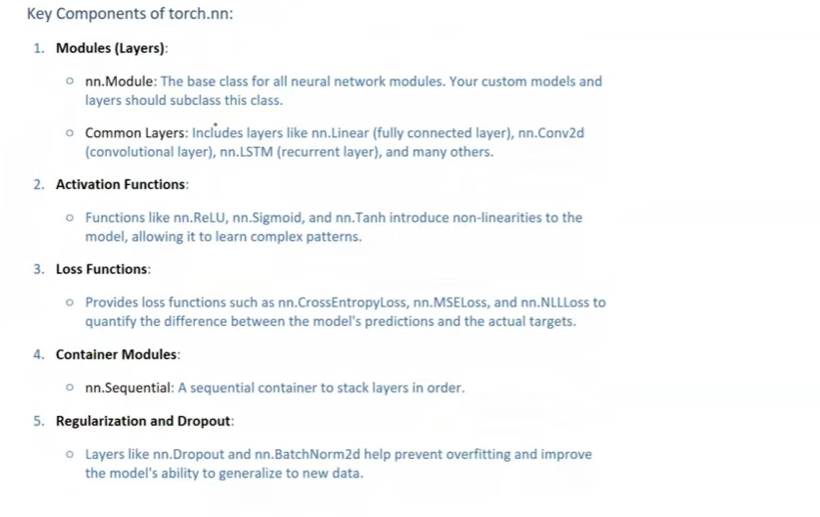

In this image, all the nn.SHITS are **CLASSES** which are found in the torch.nn subpackage.

![image.png](attachment:486bc685-3e32-4c81-8827-1186d2691bb8.png)

In [20]:
import torch
import torch.nn as nn

class Model(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        self.network=nn.Sequential(nn.Linear(num_features, 3), nn.ReLU(), nn.Linear(3,1), nn.Sigmoid())
    def forward(self, features):
        out = self.network(features)
        return out
        

In [21]:
features = torch.rand(10, 5)
model = Model(features.shape[1])
model(features) # calls the forward method automatically


tensor([[0.3478],
        [0.4706],
        [0.4445],
        [0.4460],
        [0.4169],
        [0.3831],
        [0.4276],
        [0.3823],
        [0.3847],
        [0.3920]], grad_fn=<SigmoidBackward0>)

In [22]:
from torchinfo import summary

In [23]:
summary(model, input_size = (10, 5))

Layer (type:depth-idx)                   Output Shape              Param #
Model                                    [10, 1]                   --
├─Sequential: 1-1                        [10, 1]                   --
│    └─Linear: 2-1                       [10, 3]                   18
│    └─ReLU: 2-2                         [10, 3]                   --
│    └─Linear: 2-3                       [10, 1]                   4
│    └─Sigmoid: 2-4                      [10, 1]                   --
Total params: 22
Trainable params: 22
Non-trainable params: 0
Total mult-adds (M): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00

## **A proper training pipeline using PyTorch is shown here here:**

In [6]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
import torch
import torch.nn as nn
import torch.optim as opt
df = pd.read_csv("https://raw.githubusercontent.com/gscdit/Breast-Cancer-Detection/refs/heads/master/data.csv")
df=df.drop(columns=['id','Unnamed: 32'])
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:,1:], df.iloc[:,0],test_size=0.2)
scaler = StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

X_train_tensor = torch.from_numpy(X_train.astype(np.float32))
X_test_tensor = torch.from_numpy(X_test.astype(np.float32))
y_train_tensor = torch.from_numpy(y_train.astype(np.float32))
y_test_tensor = torch.from_numpy(y_test.astype(np.float32))

# MODEL CLASS USED TO INSTANTIATE OBJECTS!
# NOTE, IT IS ALWAYS A SUBCLASS OF nn.Module!
class MLP(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        self.linear = nn.Linear(num_features, 1)
        self.sigmoid = nn.Sigmoid()
    def forward(self, features):
        out = self.linear(features)
        out = self.sigmoid(out)
        return out


lr = 0.1
epochs = 25

model = MLP(X_train_tensor.shape[1])
# MODEL OBJECT using nn.Module as base class
loss_function = nn.BCELoss() 
# BUILT-IN LOSS FUNCTION
optimizer = opt.SGD(model.parameters(), lr=lr)
# BUILT IN OPTIMIZER AND WEIGHT UPDATE

#CUSTOM TRAINING LOOP
for epoch in range(epochs):
    y_pred = model(X_train_tensor)
    loss = loss_function(y_pred, y_train_tensor.reshape(-1, 1))
    
    optimizer.zero_grad()
    # model.linear.weight.grad.zero_()
    # model.linear.bias.grad.zero_()

    
    loss.backward() #Here, loss autograd tracking
    #is obtained from a custom method dependency or .

    optimizer.step()
    # with torch.no_grad():
    #     model.linear.weight -= lr*model.linear.weight.grad
    #     model.linear.bias -= lr*model.linear.bias.grad
    
    
with torch.no_grad():
    y_pred=model(X_test_tensor)
    y_pred=(y_pred>0.9).float()
    accuracy=(y_pred==y_test_tensor).float().mean()
    print(f"Accuracy nigga: {accuracy}")
    
    
    
    
    

        
    

Accuracy nigga: 0.5387811660766602


# IV. Dataset, DataLoader classes from **torch.utils.data** for performing data transformation and MBGD (mini-batch gradient descent) rigorously.

In [17]:
from sklearn.datasets import make_classification
X, y = make_classification(n_samples = 10, n_features=2, n_informative=2, n_redundant=0, n_classes=2, random_state=4)


In [18]:
X = torch.from_numpy(X)
y=torch.from_numpy(y)

In [30]:
from torch.utils.data import Dataset, DataLoader
class CustomDataset(Dataset):
    def __init__(self, features, labels):
        self.features=features
        self.labels=labels
    def __len__(self):
        return self.features.shape[0]
    def __getitem__(self,index):
        # THIS IS WHERE YOU CAN PERFORM 
        # DATA TRANSFORMATION just before 
        # accessing a sample
        return self.features[index], self.labels[index]
ds = CustomDataset(X,y)
# len(ds)
# ds[2], ds[3]

# DATALOADER for mini-batching
# with shuffling.
dl = DataLoader(ds, batch_size=2, shuffle=True)
for batchfeatures, batchlabels in dl:
    print(batchfeatures)
    print(batchlabels)
    print("-"*50)


tensor([[ 0.9809,  0.8372],
        [ 1.0011, -1.1495]], dtype=torch.float64)
tensor([1, 1])
--------------------------------------------------
tensor([[ 0.7476, -0.7577],
        [ 1.1439, -0.9525]], dtype=torch.float64)
tensor([1, 1])
--------------------------------------------------
tensor([[-1.5121,  1.4263],
        [-0.9944, -1.3395]], dtype=torch.float64)
tensor([0, 0])
--------------------------------------------------
tensor([[ 0.2348,  1.7286],
        [-0.8155,  0.0650]], dtype=torch.float64)
tensor([1, 0])
--------------------------------------------------
tensor([[-1.1080,  1.0900],
        [-0.1569, -1.5173]], dtype=torch.float64)
tensor([0, 0])
--------------------------------------------------


What are the problems solved by torch.utils.data.Dataset and torch.utils.data.DataLoader? 
1) Standard interface - Dataset
2) Easy data transformation - Dataset
3) Shuffling and batching is easy - DataLoader
4) Parallelization in batching - DataLoader


## Samplers
in DataLoader: *Sequential*, *random* or *custom* samplers are different ways of deciding **which indices** to fetch from the dataset.


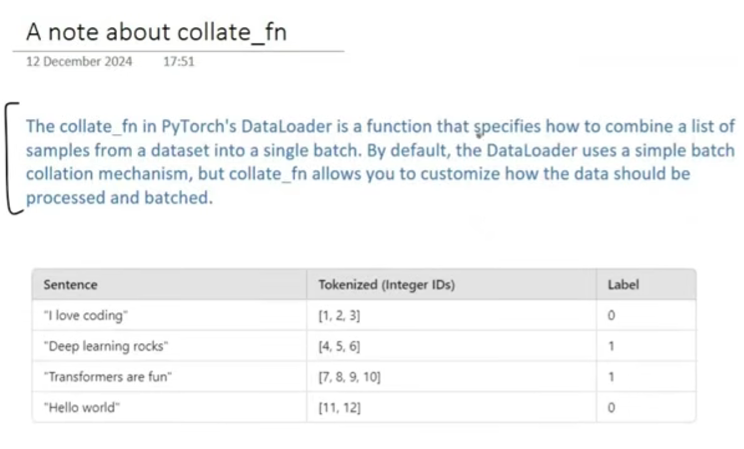

## Collate function (collate_fn)
This specifies how fetched indices should be *processed and grouped together* to form a mini-batch. For example, in NLP, we cannot simply batch normal sentences of disparate length together, we must pad the shorter sentences in the batch.

## Important parameters in DataLoader class

Dataset object, batch_size, shuffle, num_workers, pin_memory, drop_last (for dropping the remainder obtained after dividing samples into batches, collate_fn, sampler


## Refined Training Pipeline with Dataset and DataLoader, torch.nn, torch.optim 

In [6]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
import torch
import torch.nn as nn
import torch.optim as opt
from torch.utils.data import Dataset, DataLoader
df = pd.read_csv("https://raw.githubusercontent.com/gscdit/Breast-Cancer-Detection/refs/heads/master/data.csv")
df=df.drop(columns=['id','Unnamed: 32'])
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:,1:], df.iloc[:,0],test_size=0.2)
scaler = StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

X_train_tensor = torch.from_numpy(X_train.astype(np.float32))
X_test_tensor = torch.from_numpy(X_test.astype(np.float32))
y_train_tensor = torch.from_numpy(y_train.astype(np.float32))
y_test_tensor = torch.from_numpy(y_test.astype(np.float32))

# CREATE a blueprint for a dataset object
class CustomDataset(Dataset):
    def __init__(self, features, labels):
        self.features = features
        self.labels = labels
    def __len__(self):
        return len(self.features)
    def __getitem__(self, index):
        return self.features[index], self.labels[index]

# Creating a dataset object:
train_ds = CustomDataset(X_train_tensor, y_train_tensor)
test_ds = CustomDataset(X_test_tensor, y_test_tensor)

# Creating a loaded, preprocessed dataset object:
trainloader = DataLoader(train_ds, batch_size=32, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=True)

        
# MODEL CLASS USED TO INSTANTIATE OBJECTS!
# NOTE, IT IS ALWAYS A SUBCLASS OF nn.Module!
class MLP(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        self.linear = nn.Linear(num_features, 1)
        self.sigmoid = nn.Sigmoid()
    def forward(self, features):
        out = self.linear(features)
        out = self.sigmoid(out)
        return out


lr = 0.1
epochs = 25

model = MLP(X_train_tensor.shape[1])
# MODEL OBJECT using nn.Module as base class
loss_function = nn.BCELoss() 
# BUILT-IN LOSS FUNCTION
optimizer = opt.SGD(model.parameters(), lr=lr)
# BUILT IN OPTIMIZER AND WEIGHT UPDATE

#CUSTOM TRAINING LOOP
for epoch in range(epochs):
    for batchfeatures,batchlabels in trainloader:        
        #MBGD OPTIMIZATION
        y_pred = model(batchfeatures)
        loss=loss_function(y_pred, batchlabels.view(-1,1))
        # TYPICAL BGD 
        # y_pred = model(X_train_tensor)
        # loss = loss_function(y_pred, y_train_tensor.reshape(-1, 1))
        
        optimizer.zero_grad()
        # model.linear.weight.grad.zero_()
        # model.linear.bias.grad.zero_()
    
        
        loss.backward() #Here, loss autograd tracking
        #is obtained from a complex function dependency or .
    
        optimizer.step()
        # with torch.no_grad():
        #     model.linear.weight -= lr*model.linear.weight.grad
        #     model.linear.bias -= lr*model.linear.bias.grad
        
    
with torch.no_grad():
    y_pred=model(X_test_tensor)
    y_pred=(y_pred>0.9).float()
    accuracy=(y_pred==y_test_tensor).float().mean()
    print(f"Accuracy nigga: {accuracy}")
    
    
    
    
    

        
    

Accuracy nigga: 0.5323176383972168
